<a href="https://colab.research.google.com/github/THAMARAI24/CSA4705-Deep-Learning-THAMARAI-V-/blob/main/C04_Lab_Exp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    classification_report
)

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)
print("Environment Ready!")

TensorFlow Version: 2.21.0
Environment Ready!


RNN-based sentiment classification

In [2]:
# Load IMDB dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(
    num_words=10000
)

# Padding
x_train = tf.keras.preprocessing.sequence.pad_sequences(
    x_train, maxlen=200
)
x_test = tf.keras.preprocessing.sequence.pad_sequences(
    x_test, maxlen=200
)

# Build RNN model
model = models.Sequential([
    layers.Embedding(10000, 64),
    layers.SimpleRNN(64),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train
model.fit(x_train, y_train, epochs=3, batch_size=128,
          validation_split=0.2)

# Evaluate
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 106ms/step - accuracy: 0.6399 - loss: 0.6247 - val_accuracy: 0.7056 - val_loss: 0.5624
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 99ms/step - accuracy: 0.8320 - loss: 0.3837 - val_accuracy: 0.8096 - val_loss: 0.4244
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 101ms/step - accuracy: 0.9141 - loss: 0.2229 - val_accuracy: 0.7922 - val_loss: 0.4947
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7894 - loss: 0.4888
Test Loss: 0.4887751042842865
Test Accuracy: 0.7893999814987183


In [3]:
text = ("deep learning is an interesting subject. "
        "recurrent neural networks learn sequential patterns. ") * 100

chars = sorted(set(text))
char_to_id = {c:i for i,c in enumerate(chars)}
id_to_char = np.array(chars)

encoded = np.array([char_to_id[c] for c in text])

seq_length = 40

X = np.array([
    encoded[i:i+seq_length]
    for i in range(len(encoded)-seq_length)
])

y = encoded[seq_length:]

model = models.Sequential([
    layers.Embedding(len(chars), 32),
    layers.SimpleRNN(128),
    layers.Dense(len(chars))
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    )
)

model.fit(X, y, epochs=10, batch_size=64)

# Generate text
seed = "deep learning is"
result = seed

for i in range(100):
    sequence = [char_to_id.get(c, 0) for c in result[-seq_length:]]
    sequence = tf.keras.preprocessing.sequence.pad_sequences(
        [sequence], maxlen=seq_length
    )

    prediction = model.predict(sequence, verbose=0)
    next_char = np.argmax(prediction[0])

    result += id_to_char[next_char]

print("Generated Text:")
print(result)

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.9700
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0266
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0081
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0043
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0027
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0019
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0014
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0011
Epoch 9/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 8.4713e-04
Epoch 10/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 6.8811e-04
Generated Text:
deep learning isrrrrrrrrrrrrrrrrrrreeet. recurrent aernganntt.nntaauutnnna btrntial patteniertaieeaesetesne int lete


Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0556
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0048
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0030
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0022
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0018
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0016 
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0014
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0013
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0012
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0011
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
MAE: 0.047571602033102296
MSE: 0.003235087070148288
RMSE: 0.05687782582121338


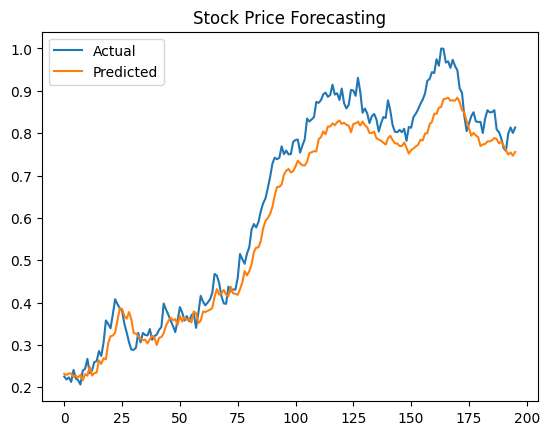

In [4]:
# Generate sample stock data
data = 100 + np.cumsum(np.random.randn(1000))

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

# Create sequences
X, y = [], []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

# Split data chronologically
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# RNN model
model = models.Sequential([
    layers.SimpleRNN(50, activation='tanh',
                     input_shape=(20, 1)),
    layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=10, batch_size=32)

# Prediction
predictions = model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

plt.plot(y_test, label='Actual')
plt.plot(predictions, label='Predicted')
plt.title("Stock Price Forecasting")
plt.legend()
plt.show()

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0188
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0076
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0068
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0065
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0061
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0059
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0057
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0055
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0053
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0052
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
MAE: 0.05600336610000864
MSE: 0.005218294175856577
RMSE: 0.07223776142611686


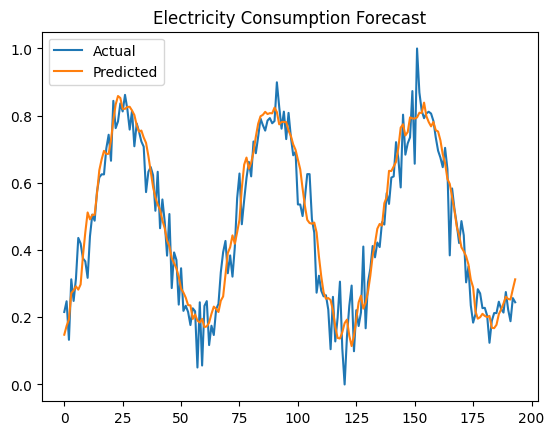

In [5]:
# Generate electricity consumption data
data = 500 + 50*np.sin(np.arange(1000)*0.1) + \
       np.random.normal(0, 10, 1000)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X, y = [], []

for i in range(30, len(data)):
    X.append(data[i-30:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = models.Sequential([
    layers.SimpleRNN(64, input_shape=(30, 1)),
    layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=10, batch_size=32)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))

plt.plot(y_test, label='Actual')
plt.plot(predictions, label='Predicted')
plt.title("Electricity Consumption Forecast")
plt.legend()
plt.show()

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Sample text
text = [
    "deep learning is interesting",
    "deep learning uses neural networks",
    "neural networks learn patterns",
    "machine learning is powerful",
    "recurrent networks process sequences"
] * 100

tokenizer = Tokenizer()
tokenizer.fit_on_texts(text)

sequences = []

for line in text:
    tokens = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(tokens)):
        sequences.append(tokens[:i+1])

max_len = max(len(seq) for seq in sequences)

sequences = pad_sequences(sequences, maxlen=max_len)

X = sequences[:, :-1]
y = sequences[:, -1]

vocab_size = len(tokenizer.word_index) + 1

model = models.Sequential([
    layers.Embedding(vocab_size, 32),
    layers.SimpleRNN(64),
    layers.Dense(vocab_size, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X, y, epochs=30, verbose=1)

# Predict next word
seed_text = "deep learning"
token_list = tokenizer.texts_to_sequences([seed_text])[0]
token_list = pad_sequences([token_list], maxlen=max_len-1)

predicted = np.argmax(model.predict(token_list, verbose=0), axis=1)[0]

for word, index in tokenizer.word_index.items():
    if index == predicted:
        print("Input:", seed_text)
        print("Predicted Next Word:", word)
        break

Epoch 1/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4313 - loss: 1.9985
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9381 - loss: 0.5760
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9406 - loss: 0.1980
Epoch 4/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9375 - loss: 0.1319
Epoch 5/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9375 - loss: 0.1145
Epoch 6/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9375 - loss: 0.1067
Epoch 7/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9375 - loss: 0.1024
Epoch 8/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9369 - loss: 0.0996
Epoch 9/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9369 - loss: 0.0977
Epoch 10/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9375 - loss: 0.0964
Epoch 11/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9375 - loss: 0.0954
Epoch 12/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9375 - lo

Input: deep learning
Predicted Next Word: uses


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
RNN MSE: 0.00938317316293233
LSTM MSE: 0.009130139275240125


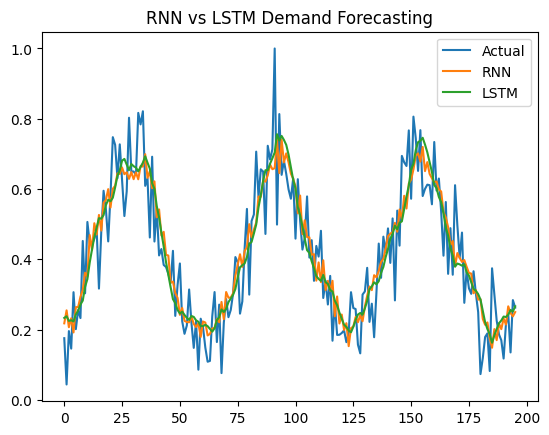

In [7]:
# Generate sample sales data
data = 200 + 30*np.sin(np.arange(1000)*0.1) + \
       np.random.normal(0, 10, 1000)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X, y = [], []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# RNN model
rnn = models.Sequential([
    layers.SimpleRNN(50, input_shape=(20, 1)),
    layers.Dense(1)
])

rnn.compile(optimizer='adam', loss='mse')
rnn.fit(X_train, y_train, epochs=10, verbose=0)

rnn_pred = rnn.predict(X_test)

# LSTM model
lstm = models.Sequential([
    layers.LSTM(50, input_shape=(20, 1)),
    layers.Dense(1)
])

lstm.compile(optimizer='adam', loss='mse')
lstm.fit(X_train, y_train, epochs=10, verbose=0)

lstm_pred = lstm.predict(X_test)

# Compare performance
print("RNN MSE:", mean_squared_error(y_test, rnn_pred))
print("LSTM MSE:", mean_squared_error(y_test, lstm_pred))

plt.plot(y_test, label='Actual')
plt.plot(rnn_pred, label='RNN')
plt.plot(lstm_pred, label='LSTM')
plt.title("RNN vs LSTM Demand Forecasting")
plt.legend()
plt.show()

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0367
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0039
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0024
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0020
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0018
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0017
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0016
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0016
Epoch 9/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0015
Epoch 10/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0015
Epoch 11/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0014
Epoch 12/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0014
Epoch 13/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0014
Epoch 14/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0013
Epoch 15/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0013
7/7 ━━━━━━━━━━━

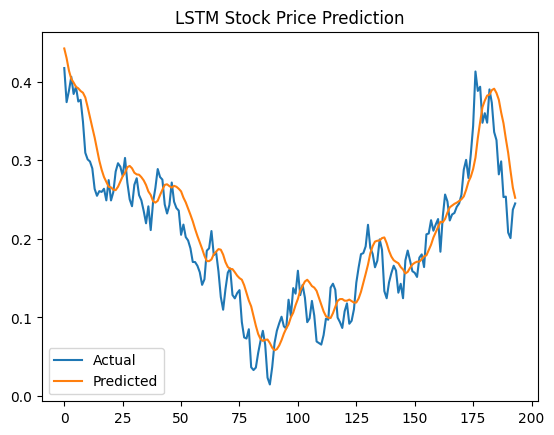

In [8]:
# Generate sample stock data
data = 100 + np.cumsum(np.random.randn(1000))

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X, y = [], []

for i in range(30, len(data)):
    X.append(data[i-30:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# LSTM model
model = models.Sequential([
    layers.LSTM(64, input_shape=(30, 1)),
    layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=15, batch_size=32)

predictions = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))

plt.plot(y_test, label='Actual')
plt.plot(predictions, label='Predicted')
plt.title("LSTM Stock Price Prediction")
plt.legend()
plt.show()

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0440
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0089
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0063
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0059
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0058
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0057
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0057
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0057
Epoch 9/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0057
Epoch 10/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0057
Epoch 11/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0057
Epoch 12/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0057
Epoch 13/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0057
Epoch 14/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0057
Epoch 15/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0057
7/7 ━━━━━━━━━━━

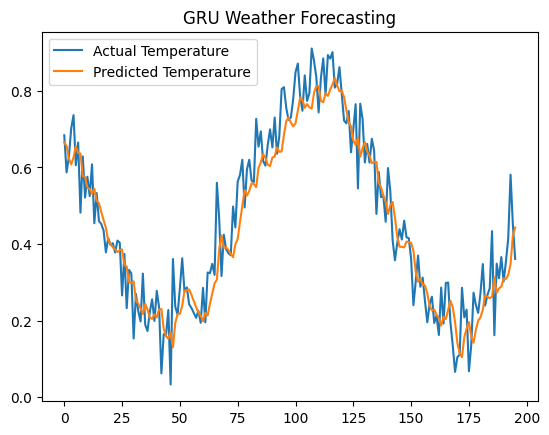

In [9]:
# Generate multivariate weather data
n = 1000
t = np.arange(n)

temperature = 25 + 5*np.sin(t*0.05) + np.random.normal(0, 1, n)
humidity = 60 + 10*np.sin(t*0.03) + np.random.normal(0, 2, n)
pressure = 1013 + 5*np.sin(t*0.02) + np.random.normal(0, 1, n)

data = np.column_stack((temperature, humidity, pressure))

scaler = MinMaxScaler()
data = scaler.fit_transform(data)

X, y = [], []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i, 0])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# GRU model
model = models.Sequential([
    layers.GRU(64, input_shape=(20, 3)),
    layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=15, batch_size=32)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))

plt.plot(y_test, label='Actual Temperature')
plt.plot(predictions, label='Predicted Temperature')
plt.title("GRU Weather Forecasting")
plt.legend()
plt.show()

In [10]:
# Generate dataset
data = 100 + 20*np.sin(np.arange(1000)*0.1) + \
       np.random.normal(0, 5, 1000)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X, y = [], []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# RNN
rnn = models.Sequential([
    layers.SimpleRNN(50, input_shape=(20, 1)),
    layers.Dense(1)
])

# LSTM
lstm = models.Sequential([
    layers.LSTM(50, input_shape=(20, 1)),
    layers.Dense(1)
])

# GRU
gru = models.Sequential([
    layers.GRU(50, input_shape=(20, 1)),
    layers.Dense(1)
])

models_list = [('RNN', rnn), ('LSTM', lstm), ('GRU', gru)]

for name, model in models_list:
    model.compile(optimizer='adam', loss='mse')
    model.fit(X_train, y_train, epochs=10, verbose=0)

    prediction = model.predict(X_test, verbose=0)

    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)

    print(name)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("----------------")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


RNN
MSE: 0.006287369655544718
RMSE: 0.07929293572282917
----------------
LSTM
MSE: 0.0055898006903631154
RMSE: 0.07476496967406003
----------------
GRU
MSE: 0.006799456506181442
RMSE: 0.08245881703117891
----------------


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_7 (SimpleRNN)        │ (None, 20, 64)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_8 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,489 (29.25 KB)

 Trainable params: 7,489 (29.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.1006
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0086
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0056
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0045
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0041
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0040
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0036
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0033
Epoch 9/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0032
Epoch 10/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0032
Epoch 11/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0031
Epoch 12/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0031
Epoch 13/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0031
Epoch 14/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0030
Epoch 15/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0030
7/7 

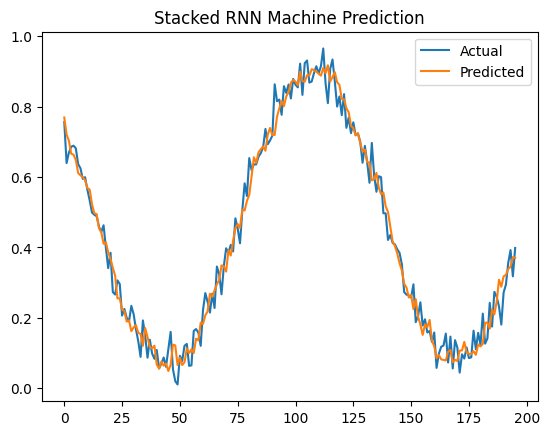

In [11]:
# Generate machine sensor data
n = 1000
t = np.arange(n)

temperature = 50 + 10*np.sin(t*0.05) + np.random.normal(0, 1, n)
pressure = 30 + 5*np.sin(t*0.03) + np.random.normal(0, 1, n)
vibration = 5 + 2*np.sin(t*0.02) + np.random.normal(0, 0.5, n)

data = np.column_stack((temperature, pressure, vibration))

scaler = MinMaxScaler()
data = scaler.fit_transform(data)

X, y = [], []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i, 0])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Stacked RNN model
model = models.Sequential([
    layers.SimpleRNN(64, return_sequences=True,
                     input_shape=(20, 3)),
    layers.SimpleRNN(32),
    layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.summary()

model.fit(X_train, y_train, epochs=15, batch_size=32)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("MSE:", mean_squared_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))

plt.plot(y_test, label='Actual')
plt.plot(predictions, label='Predicted')
plt.title("Stacked RNN Machine Prediction")
plt.legend()
plt.show()

Gradient values:
Time step 1 : 0.5
Time step 2 : 0.25
Time step 3 : 0.125
Time step 4 : 0.0625
Time step 5 : 0.03125
Time step 6 : 0.015625
Time step 7 : 0.0078125
Time step 8 : 0.00390625
Time step 9 : 0.001953125
Time step 10 : 0.0009765625
Time step 11 : 0.00048828125
Time step 12 : 0.000244140625
Time step 13 : 0.0001220703125
Time step 14 : 6.103515625e-05
Time step 15 : 3.0517578125e-05
Time step 16 : 1.52587890625e-05
Time step 17 : 7.62939453125e-06
Time step 18 : 3.814697265625e-06
Time step 19 : 1.9073486328125e-06
Time step 20 : 9.5367431640625e-07
Time step 21 : 4.76837158203125e-07
Time step 22 : 2.384185791015625e-07
Time step 23 : 1.1920928955078125e-07
Time step 24 : 5.960464477539063e-08
Time step 25 : 2.9802322387695312e-08
Time step 26 : 1.4901161193847656e-08
Time step 27 : 7.450580596923828e-09
Time step 28 : 3.725290298461914e-09
Time step 29 : 1.862645149230957e-09
Time step 30 : 9.313225746154785e-10


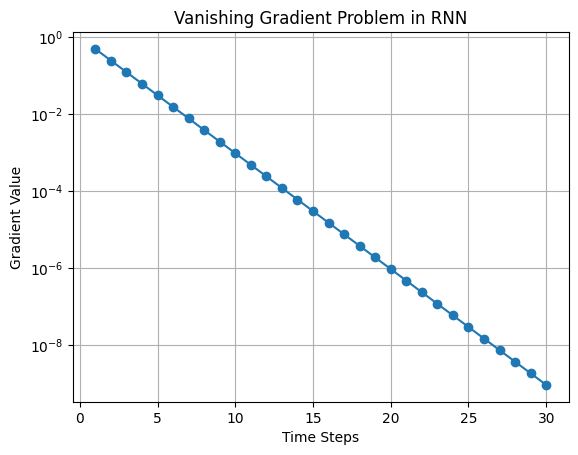

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Simulate gradient values
steps = 30
gradient = 1.0
gradients = []

for i in range(steps):
    gradient = gradient * 0.5
    gradients.append(gradient)

print("Gradient values:")
for i, value in enumerate(gradients):
    print("Time step", i+1, ":", value)

# Plot gradient
plt.plot(range(1, steps+1), gradients, marker='o')
plt.yscale('log')
plt.xlabel("Time Steps")
plt.ylabel("Gradient Value")
plt.title("Vanishing Gradient Problem in RNN")
plt.grid()
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sequence Length: 5
MSE: 0.01186075568797877


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sequence Length: 10
MSE: 0.008515802168796442


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sequence Length: 20
MSE: 0.009620458864153076


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sequence Length: 30
MSE: 0.0091726507569279


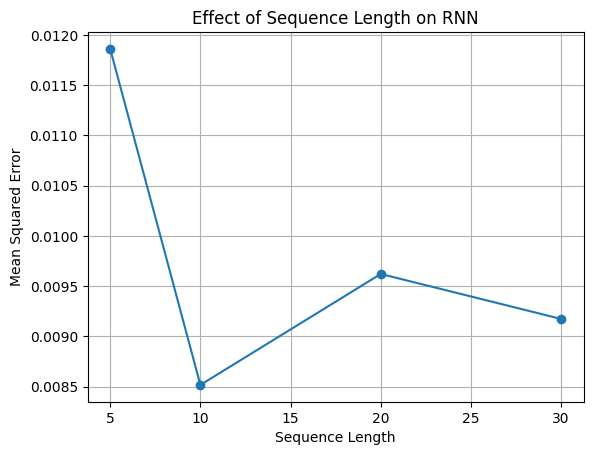

In [13]:
# Generate time-series data
data = 100 + 20*np.sin(np.arange(1000)*0.1) + \
       np.random.normal(0, 5, 1000)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

sequence_lengths = [5, 10, 20, 30]
results = []

for seq_len in sequence_lengths:

    X, y = [], []

    for i in range(seq_len, len(data)):
        X.append(data[i-seq_len:i])
        y.append(data[i])

    X = np.array(X)
    y = np.array(y)

    split = int(0.8 * len(X))

    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    model = models.Sequential([
        layers.SimpleRNN(50, input_shape=(seq_len, 1)),
        layers.Dense(1)
    ])

    model.compile(optimizer='adam', loss='mse')

    model.fit(X_train, y_train, epochs=5, verbose=0)

    predictions = model.predict(X_test, verbose=0)

    mse = mean_squared_error(y_test, predictions)
    results.append(mse)

    print("Sequence Length:", seq_len)
    print("MSE:", mse)

# Plot comparison
plt.plot(sequence_lengths, results, marker='o')
plt.xlabel("Sequence Length")
plt.ylabel("Mean Squared Error")
plt.title("Effect of Sequence Length on RNN")
plt.grid()
plt.show()

In [14]:
# Generate sample data
data = 100 + 20*np.sin(np.arange(1000)*0.1) + \
       np.random.normal(0, 5, 1000)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X, y = [], []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

learning_rates = [0.001, 0.01]
hidden_units = [32, 64]
batch_sizes = [16, 32]

best_mse = float('inf')
best_config = None

for lr in learning_rates:
    for units in hidden_units:
        for batch in batch_sizes:

            model = models.Sequential([
                layers.LSTM(units, input_shape=(20, 1)),
                layers.Dense(1)
            ])

            optimizer = tf.keras.optimizers.Adam(
                learning_rate=lr
            )

            model.compile(optimizer=optimizer, loss='mse')

            model.fit(
                X_train, y_train,
                epochs=5,
                batch_size=batch,
                verbose=0
            )

            predictions = model.predict(X_test, verbose=0)

            mse = mean_squared_error(y_test, predictions)

            print("Learning Rate:", lr,
                  "Hidden Units:", units,
                  "Batch Size:", batch,
                  "MSE:", mse)

            if mse < best_mse:
                best_mse = mse
                best_config = (lr, units, batch)

print("\nBest Configuration:", best_config)
print("Best MSE:", best_mse)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Learning Rate: 0.001 Hidden Units: 32 Batch Size: 16 MSE: 0.0065860064057642305


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Learning Rate: 0.001 Hidden Units: 32 Batch Size: 32 MSE: 0.008324112049050598


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Learning Rate: 0.001 Hidden Units: 64 Batch Size: 16 MSE: 0.006781351398643638


... (6 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Learning Rate: 0.01 Hidden Units: 64 Batch Size: 16 MSE: 0.007296570256496812


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Learning Rate: 0.01 Hidden Units: 64 Batch Size: 32 MSE: 0.008089046857237873

Best Configuration: (0.001, 32, 16)
Best MSE: 0.0065860064057642305


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Mean Absolute Error: 0.06344253380838304
Mean Squared Error: 0.006188156206314043
Root Mean Squared Error: 0.07866483462331847


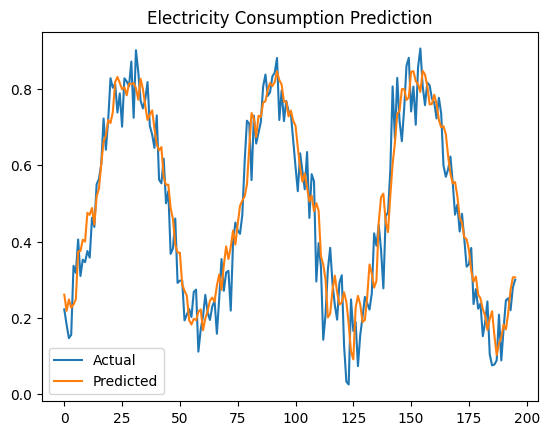

In [15]:
# Generate electricity consumption data
data = 500 + 50*np.sin(np.arange(1000)*0.1) + \
       np.random.normal(0, 10, 1000)

scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, 1))

X, y = [], []

for i in range(20, len(data)):
    X.append(data[i-20:i])
    y.append(data[i])

X = np.array(X)
y = np.array(y)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# RNN model
model = models.Sequential([
    layers.SimpleRNN(50, input_shape=(20, 1)),
    layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=10, verbose=0)

predictions = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

plt.plot(y_test, label='Actual')
plt.plot(predictions, label='Predicted')
plt.title("Electricity Consumption Prediction")
plt.legend()
plt.show()

In [17]:
# Load Reuters text dataset as a multi-class
# text classification demonstration
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.reuters.load_data(
    num_words=5000
)

# Padding
x_train = tf.keras.preprocessing.sequence.pad_sequences(
    x_train, maxlen=100
)

x_test = tf.keras.preprocessing.sequence.pad_sequences(
    x_test, maxlen=100
)

# Cast to standard Python int to prevent Keras units type validation error
num_classes = int(np.max(y_train) + 1)

# Build RNN model
model = models.Sequential([
    layers.Embedding(5000, 64),
    layers.SimpleRNN(64),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train
model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# Predict
predictions = model.predict(x_test)
y_pred = np.argmax(predictions, axis=1)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_15 (SimpleRNN)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.3350 - loss: 2.4939 - val_accuracy: 0.3868 - val_loss: 2.2488
Epoch 2/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.4437 - loss: 2.1455 - val_accuracy: 0.4346 - val_loss: 2.1911
Epoch 3/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.5450 - loss: 1.8225 - val_accuracy: 0.4713 - val_loss: 1.9905
Epoch 4/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.6232 - loss: 1.4940 - val_accuracy: 0.5164 - val_loss: 1.9141
Epoch 5/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.6816 - loss: 1.2666 - val_accuracy: 0.5025 - val_loss: 2.0165
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
Accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        12
           1       0.22      0.37      0.27       105
           2       0.00      0.00      0.00        20
           3       0.67      0.81      0.73       813
           

In [18]:
# Sample tree-structured sentiment dataset
# 1 = Positive, 0 = Negative

words = [
    "good", "bad", "excellent", "poor",
    "happy", "sad", "great", "terrible"
]

word_to_id = {word: i+1 for i, word in enumerate(words)}

sentences = [
    ("good", "excellent", 1),
    ("happy", "great", 1),
    ("excellent", "good", 1),
    ("bad", "poor", 0),
    ("sad", "terrible", 0),
    ("poor", "bad", 0)
]

left = np.array([word_to_id[a] for a, b, c in sentences])
right = np.array([word_to_id[b] for a, b, c in sentences])
labels = np.array([c for a, b, c in sentences])

# Recursive composition model
input_left = layers.Input(shape=(), dtype='int32')
input_right = layers.Input(shape=(), dtype='int32')

embedding = layers.Embedding(len(words)+1, 16)

left_vector = embedding(input_left)
right_vector = embedding(input_right)

# Combine child nodes
combined = layers.Concatenate()([
    left_vector, right_vector
])

# Parent node representation
hidden = layers.Dense(16, activation='tanh')(combined)

output = layers.Dense(1, activation='sigmoid')(hidden)

model = models.Model(
    inputs=[input_left, input_right],
    outputs=output
)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train model
model.fit(
    [left, right],
    labels,
    epochs=100,
    batch_size=2,
    verbose=1
)

# Predictions
predictions = model.predict([left, right])

predicted_classes = (predictions > 0.5).astype(int)

print("\nSentiment Classification Results:")

for i in range(len(sentences)):
    print(
        sentences[i][0], "+", sentences[i][1],
        "Actual:", labels[i],
        "Predicted:", predicted_classes[i][0]
    )

print("\nAccuracy:",
      accuracy_score(labels, predicted_classes))

Model: "functional_27"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_27      │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_28      │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 16)        │        144 │ input_layer_27[0… │
│ (Embedding)         │                   │            │ input_layer_28[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32)        │          0 │ embedding_5[0][0… │
│ (Concatenate)       │                   │            │ embedding_5[1][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 16)        │        528 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 1)         │         17 │ dense_27[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 689 (2.69 KB)

 Trainable params: 689 (2.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6667 - loss: 0.6881
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6667 - loss: 0.6794
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8333 - loss: 0.6715
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8333 - loss: 0.6634
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 1.0000 - loss: 0.6550 
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 1.0000 - loss: 0.6462 
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.6370 
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 1.0000 - loss: 0.6271
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.6165 
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 1.0000 - loss: 0.6051
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.5929 
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 1.0000